# 03 · Evaluation (Milestone 3)

Reads `results/` written by `src/evaluate.py`, `src/attention.py` and `src/cycle.py`; figures are saved to
`results/figures/` (PNG + PDF for the IEEE report). Produce everything on the cluster with `bash scripts/round2.sh`.

- **Round 1**: one seed, 10 epochs (runs named `prefix_lora`, ...). Every run hit the epoch limit without early stopping.
- **Round 2**: up to 40 epochs with early stopping (patience 3), 3 seeds per config (`prefix_lora_s0..s2`),
  95% bootstrap intervals, no-repeat decoding, data-size runs, attention maps and the image→caption→image cycle.

Required metrics: BLEU, METEOR, ROUGE-L, CIDEr. Extras: CHAIR, gender-word error, CLIPScore, efficiency, repetition.

In [1]:
# Run from the repo root (works whether Jupyter starts in notebooks/ or the root).
import warnings; warnings.filterwarnings("ignore", message="IProgress not found")  # tqdm without ipywidgets
import os, sys, re, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, torch, transformers
from IPython.display import Image as Show, display
print("torch", torch.__version__, "| transformers", transformers.__version__)
FIG = Path("results/figures"); FIG.mkdir(parents=True, exist_ok=True)

torch 2.15.0+cpu | transformers 4.57.6


In [2]:
import matplotlib.pyplot as plt
# Fixed categorical order (validated reference palette); recessive grid, no top/right spines.
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, MUTED, GRID = "#52514e", "#9a9893", "#e4e3df"
plt.rcParams.update({"axes.prop_cycle": plt.cycler(color=SERIES), "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.color": GRID,
                     "grid.linewidth": 0.8, "axes.edgecolor": MUTED, "axes.labelcolor": INK,
                     "xtick.color": INK, "ytick.color": INK, "lines.linewidth": 2,
                     "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight", "font.size": 10})
COLOR = {"prefix": SERIES[0], "cross_attention": SERIES[1]}          # colour follows the injection method
def save(fig, name):
    fig.savefig(FIG / f"{name}.png"); fig.savefig(FIG / f"{name}.pdf"); plt.show()

In [3]:
df = pd.read_csv("results/metrics.csv")
df = df[df.split == "test"].copy()
def tag(name):
    if name.startswith("baseline_"): return "baseline", name, None, None
    m = re.fullmatch(r"(.+)_n(\d+)_s(\d+)", name)
    if m: return "scale", m.group(1), int(m.group(2)), int(m.group(3))
    m = re.fullmatch(r"(.+)_s(\d+)", name)
    if m: return "round2", m.group(1), 4000, int(m.group(2))
    return "round1", name, 4000, None
df[["round", "exp", "train_images", "seed"]] = df.name.apply(lambda n: pd.Series(tag(n)))
r2, base = df[df["round"] == "round2"], df[df["round"] == "baseline"]
summ = {p.parent.name: json.loads(p.read_text()) for p in Path("runs").glob("*/summary.json")}
print(df.groupby("round").name.nunique().to_dict(), "runs per round")

QUALITY = ["BLEU-4", "METEOR", "ROUGE-L", "CIDEr", "CLIPScore", "CHAIR-s"]
def mean_std(d, cols, by=("exp",)):
    g = d.groupby(list(by))[cols]
    out = g.mean().round(3).astype(str) + " ± " + g.std().round(3).astype(str)
    out["seeds"] = g.size()
    return out

{'baseline': 2, 'round1': 6, 'round2': 18, 'scale': 12} runs per round


## 1 · Fine-tuning strategy × injection method (beam search, width 3)

Mean ± standard deviation over 3 training seeds. Efficiency columns come from the training summaries.

In [4]:
main = r2[r2.decode == "beam_w3"]
t = mean_std(main, QUALITY)
eff = pd.DataFrame({e: {k: np.mean([summ[f"{e}_s{s}"][k] for s in range(3) if f"{e}_s{s}" in summ])
                        for k in ("trainable", "epochs_run", "mean_epoch_time_s", "peak_mem_gb")}
                    for e in t.index}).T
eff["trainable"] = (eff.trainable / 1e6).round(2).astype(str) + "M"
r1 = df[(df["round"] == "round1") & (df.decode == "beam_w3")].set_index("exp").CIDEr.rename("CIDEr round 1 (10 ep)")
b = base.set_index("name")[QUALITY].round(3)
display(t.join(eff).join(r1).sort_values("CIDEr", ascending=False)); display(b)

,BLEU-4,METEOR,ROUGE-L,CIDEr,CLIPScore,CHAIR-s,seeds,trainable,epochs_run,mean_epoch_time_s,peak_mem_gb,CIDEr round 1 (10 ep)
exp,,,,,,,,,,,,
xattn_lora,0.269 ± 0.001,0.238 ± 0.003,0.509 ± 0.0,0.907 ± 0.011,0.709 ± 0.003,0.168 ± 0.016,3,29.4M,17.000000,7.966667,3.050765,0.8381
prefix_lora,0.267 ± 0.003,0.233 ± 0.001,0.51 ± 0.002,0.898 ± 0.01,0.725 ± 0.002,0.182 ± 0.008,3,31.91M,17.000000,6.300000,2.453981,0.8742
prefix_full,0.264 ± 0.008,0.233 ± 0.002,0.503 ± 0.002,0.897 ± 0.008,0.717 ± 0.003,0.214 ± 0.017,3,155.91M,14.000000,8.466667,3.742748,0.9124
xattn_frozen,0.269 ± 0.003,0.234 ± 0.004,0.508 ± 0.006,0.888 ± 0.014,0.705 ± 0.001,0.187 ± 0.009,3,28.96M,17.333333,6.433333,2.964235,0.8233
xattn_full,0.259 ± 0.006,0.236 ± 0.003,0.503 ± 0.003,0.881 ± 0.011,0.706 ± 0.004,0.18 ± 0.023,3,153.4M,12.666667,9.300000,4.525756,0.8678
prefix_frozen,0.246 ± 0.002,0.218 ± 0.003,0.5 ± 0.006,0.819 ± 0.006,0.713 ± 0.001,0.165 ± 0.01,3,31.47M,16.000000,5.100000,2.391469,0.7883


,BLEU-4,METEOR,ROUGE-L,CIDEr,CLIPScore,CHAIR-s
name,,,,,,
baseline_retrieval,0.134,0.184,0.392,0.507,0.674,0.252
baseline_blip2,0.370,0.278,0.582,1.268,0.750,0.042


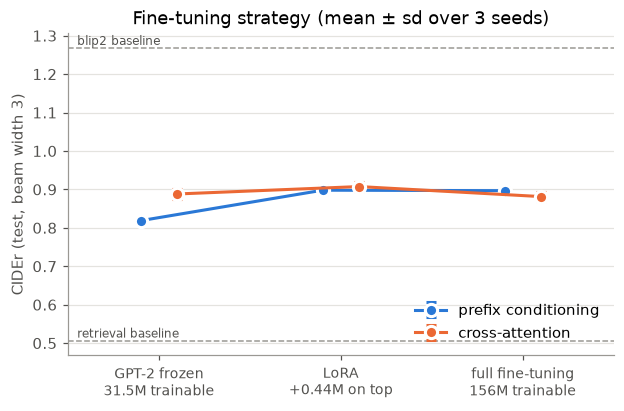

In [5]:
# CIDEr per fine-tuning strategy; the tick labels say what each strategy trains (prefix model counts)
pts = main.groupby("exp").agg(CIDEr=("CIDEr", "mean"), sd=("CIDEr", "std"), injection=("injection", "first"),
                              finetune=("finetune", "first"), trainable=("trainable", "first"))
ORDER = ["prefix", "lora", "full"]
pp = pts[pts.injection == "prefix"].set_index("finetune").trainable
frozen_n = pp.get("prefix", np.nan)
ticks = [f"GPT-2 frozen\n{frozen_n / 1e6:.1f}M trainable",
         f"LoRA\n+{(pp.get('lora', np.nan) - frozen_n) / 1e6:.2f}M on top",
         f"full fine-tuning\n{pp.get('full', np.nan) / 1e6:.0f}M trainable"]
fig, ax = plt.subplots(figsize=(6.4, 3.8))
for k, (inj, g) in enumerate(pts.groupby("injection", sort=False)):
    g = g.set_index("finetune").reindex(ORDER)
    x = np.arange(3) + (-0.1 if inj == "prefix" else 0.1)
    ax.errorbar(x, g.CIDEr, yerr=g.sd, fmt="o-", ms=8, color=COLOR[inj], capsize=3, mec="white", mew=2,
                label="prefix conditioning" if inj == "prefix" else "cross-attention", zorder=3)
for _, r in base.iterrows():
    ax.axhline(r.CIDEr, color=MUTED, ls="--", lw=1)
    ax.text(-0.45, r.CIDEr, f"{r.decode} baseline", va="bottom", fontsize=8, color=INK)
ax.set_xticks(range(3)); ax.set_xticklabels(ticks, fontsize=9); ax.set_xlim(-0.5, 2.5); ax.grid(axis="x", visible=False)
ax.set(ylabel="CIDEr (test, beam width 3)", title="Fine-tuning strategy (mean ± sd over 3 seeds)")
ax.legend(frameon=False, loc="lower right"); save(fig, "params_vs_cider")

### Is a difference real? Paired bootstrap over the 500 test images

Per-image CIDEr of seed 0, resampled 1,000 times. A difference counts when its 95% interval excludes 0.

In [6]:
from src.evaluate import paired_bootstrap
def per_image(name, spec="beam_w3"):
    p = Path("results") / name / f"{spec}_test.json"
    return json.loads(p.read_text())["per_image"]["CIDEr"] if p.exists() else None
pairs = [("prefix_lora", "prefix_frozen"), ("prefix_full", "prefix_lora"), ("prefix_full", "prefix_frozen"),
         ("xattn_lora", "xattn_frozen"), ("xattn_full", "xattn_lora"),
         ("prefix_frozen", "xattn_frozen"), ("prefix_lora", "xattn_lora"), ("prefix_full", "xattn_full")]
rows = []
for a, b_ in pairs:
    x, y = per_image(f"{a}_s0"), per_image(f"{b_}_s0")
    if x and y:
        rows.append({"A": a, "B": b_, **paired_bootstrap(x, y), })
sig = pd.DataFrame(rows)
if len(sig): sig["significant"] = (sig.lo > 0) | (sig.hi < 0)
sig

,A,B,diff,lo,hi,p_not_better,significant
0,prefix_lora,prefix_frozen,0.0732,0.0303,0.1197,0.001,True
1,prefix_full,prefix_lora,0.0106,-0.0322,0.0537,0.315,False
2,prefix_full,prefix_frozen,0.0838,0.0324,0.1349,0.000,True
3,xattn_lora,xattn_frozen,0.0231,-0.0187,0.0644,0.138,False
4,xattn_full,xattn_lora,-0.0279,-0.0693,0.0148,0.899,False
5,prefix_frozen,xattn_frozen,-0.0634,-0.1198,-0.0083,0.989,True
6,prefix_lora,xattn_lora,-0.0132,-0.0636,0.0367,0.693,False
7,prefix_full,xattn_full,0.0253,-0.0290,0.0783,0.192,False


## 2 · Decoding sensitivity (prefix_lora, seed 0)

Beam width and sampling temperature, one at a time. Nucleus rows average 3 sampling seeds.

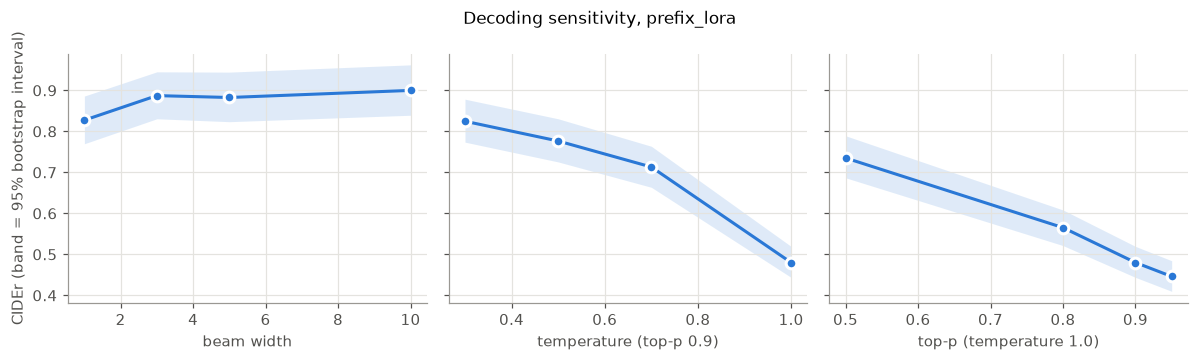

In [7]:
sw = df[df.name == "prefix_lora_s0"]
beam = sw[sw.decode.str.fullmatch(r"beam_w\d+")].assign(w=lambda d: d.decode.str.extract(r"w(\d+)")[0].astype(int)).sort_values("w")
temp = sw[sw.decode.str.fullmatch(r"nucleus_p0\.9_t[\d.]+")].assign(t=lambda d: d.decode.str.extract(r"t([\d.]+)")[0].astype(float)).sort_values("t")
topp = sw[sw.decode.str.fullmatch(r"nucleus_p[\d.]+_t1\.0")].assign(p=lambda d: d.decode.str.extract(r"p([\d.]+)")[0].astype(float)).sort_values("p")
fig, axes = plt.subplots(1, 3, figsize=(11, 3.3), sharey=True)
for ax, d, x, lab in [(axes[0], beam, "w", "beam width"), (axes[1], temp, "t", "temperature (top-p 0.9)"),
                      (axes[2], topp, "p", "top-p (temperature 1.0)")]:
    if len(d):
        ax.fill_between(d[x], d["CIDEr_lo"], d["CIDEr_hi"], color=SERIES[0], alpha=0.15, lw=0)
        ax.plot(d[x], d.CIDEr, marker="o", ms=7, color=SERIES[0], mec="white", mew=2)
    ax.set(xlabel=lab)
axes[0].set(ylabel="CIDEr (band = 95% bootstrap interval)")
fig.suptitle("Decoding sensitivity, prefix_lora", fontsize=11); plt.tight_layout(); save(fig, "decoding_sensitivity")

Accuracy against diversity: every decoding setting as one point. Up and to the right is better on both.

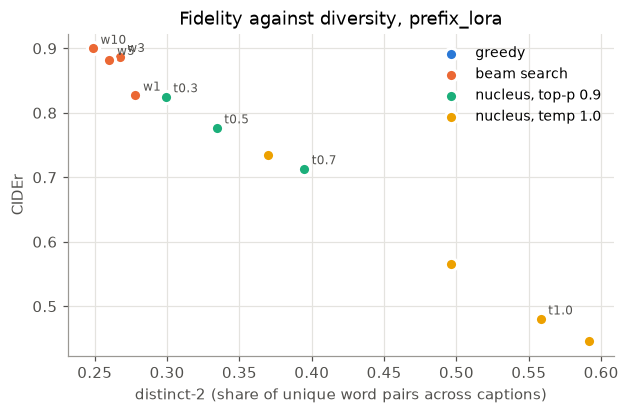

In [8]:
fig, ax = plt.subplots(figsize=(6.4, 3.8))
groups = [("greedy", sw[sw.decode == "greedy"]), ("beam search", beam), ("nucleus, top-p 0.9", temp), ("nucleus, temp 1.0", topp)]
for k, (label, g) in enumerate(groups):
    ax.scatter(g["distinct-2"], g.CIDEr, s=64, color=SERIES[k], label=label, edgecolor="white", linewidth=2, zorder=3)
for _, r in pd.concat([beam, temp]).iterrows():
    ax.annotate(r.decode.replace("nucleus_p0.9_", "").replace("beam_", ""), (r["distinct-2"], r.CIDEr),
                xytext=(5, 3), textcoords="offset points", fontsize=8, color=INK)
ax.set(xlabel="distinct-2 (share of unique word pairs across captions)", ylabel="CIDEr",
       title="Fidelity against diversity, prefix_lora")
ax.legend(frameon=False, fontsize=9); save(fig, "fidelity_vs_diversity")

## 3 · No-repeat n-gram blocking

`_nr3` forbids any 3-gram from appearing twice in a caption. `rep-3` = share of captions that repeat a 3-gram inside
themselves; `top_4gram_share` = share of captions containing the most common 4-word phrase (a template measure,
which blocking does not target). Means over every round-2 run (6 configs × 3 seeds).

In [9]:
nr = r2[r2.decode.isin(["greedy", "greedy_nr3", "beam_w3", "beam_w3_nr3"])]
nr.groupby("decode")[["CIDEr", "BLEU-4", "CHAIR-s", "rep-3", "top_4gram_share", "distinct-2"]].mean().round(4)

,CIDEr,BLEU-4,CHAIR-s,rep-3,top_4gram_share,distinct-2
decode,,,,,,
beam_w3,0.8817,0.2625,0.1826,0.0369,0.1054,0.2395
beam_w3_nr3,0.8856,0.2644,0.1847,0.0230,0.1054,0.2439
greedy,0.8261,0.2434,0.2083,0.0469,0.0746,0.2555
greedy_nr3,0.8286,0.2441,0.2084,0.0319,0.0747,0.2599


In [10]:
nr.groupby(["exp", "decode"])[["CIDEr", "rep-3"]].mean().unstack("decode").round(3)

CIDEr                                 rep-3              \
decode        beam_w3 beam_w3_nr3 greedy greedy_nr3 beam_w3 beam_w3_nr3   
exp                                                                       
prefix_frozen   0.819       0.827  0.803      0.807   0.062       0.048   
prefix_full     0.897       0.900  0.858      0.859   0.023       0.013   
prefix_lora     0.898       0.901  0.833      0.836   0.039       0.025   
xattn_frozen    0.888       0.891  0.828      0.831   0.035       0.020   
xattn_full      0.881       0.885  0.805      0.807   0.032       0.017   
xattn_lora      0.907       0.910  0.830      0.832   0.030       0.015   

                                 
decode        greedy greedy_nr3  
exp                              
prefix_frozen  0.073      0.058  
prefix_full    0.028      0.017  
prefix_lora    0.049      0.031  
xattn_frozen   0.051      0.032  
xattn_full     0.036      0.027  
xattn_lora     0.044      0.027

## 4 · How much does more data help?

The same configs trained on the first 1k / 2k / 4k training images (nested subsets), 3 seeds each, beam width 3.

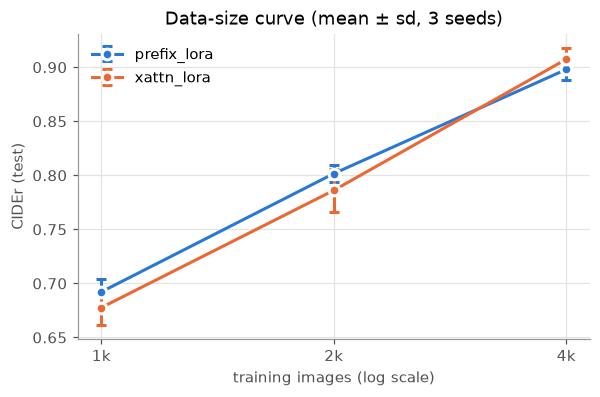

,exp,train_images,mean,std,size
0,prefix_lora,1000.0,0.692,0.012,3
1,prefix_lora,2000.0,0.802,0.008,3
2,prefix_lora,4000.0,0.898,0.010,3
3,xattn_lora,1000.0,0.678,0.016,3
4,xattn_lora,2000.0,0.786,0.020,3
5,xattn_lora,4000.0,0.907,0.011,3


In [11]:
sc = df[df["round"].isin(["scale", "round2"]) & (df.decode == "beam_w3") & df.exp.isin(["prefix_lora", "xattn_lora"])]
curve = sc.groupby(["exp", "train_images"]).CIDEr.agg(["mean", "std", "size"]).reset_index()
fig, ax = plt.subplots(figsize=(6.0, 3.6))
for exp, g in curve.groupby("exp"):
    inj = "prefix" if exp.startswith("prefix") else "cross_attention"
    ax.errorbar(g.train_images, g["mean"], yerr=g["std"], marker="o", ms=7, capsize=3, color=COLOR[inj],
                mec="white", mew=2, label=exp)
ax.set_xscale("log"); ax.minorticks_off(); ax.set_xticks([1000, 2000, 4000]); ax.set_xticklabels(["1k", "2k", "4k"])
ax.set(xlabel="training images (log scale)", ylabel="CIDEr (test)", title="Data-size curve (mean ± sd, 3 seeds)")
ax.legend(frameon=False); save(fig, "data_scaling")
curve.round(3)

## 5 · Hallucination and gender words (extra)

- **CHAIR-i**: share of mentioned objects that are not in the image · **CHAIR-s**: share of captions with one
- **gender_error**: on images whose references agree on a gender, share of captions using the opposite word
- **gender_neutral**: share using no gender word at all

In [12]:
hb = mean_std(main, ["CHAIR-i", "CHAIR-s", "gender_error", "gender_neutral", "CLIPScore"])
display(hb); base.set_index("name")[["CHAIR-i", "CHAIR-s", "gender_error", "gender_neutral", "CLIPScore"]].round(3)

,CHAIR-i,CHAIR-s,gender_error,gender_neutral,CLIPScore,seeds
exp,,,,,,
prefix_frozen,0.13 ± 0.011,0.165 ± 0.01,0.041 ± 0.018,0.307 ± 0.028,0.713 ± 0.001,3
prefix_full,0.156 ± 0.011,0.214 ± 0.017,0.041 ± 0.018,0.316 ± 0.054,0.717 ± 0.003,3
prefix_lora,0.135 ± 0.006,0.182 ± 0.008,0.041 ± 0.01,0.283 ± 0.032,0.725 ± 0.002,3
xattn_frozen,0.136 ± 0.008,0.187 ± 0.009,0.059 ± 0.014,0.201 ± 0.014,0.705 ± 0.001,3
xattn_full,0.132 ± 0.014,0.18 ± 0.023,0.059 ± 0.01,0.254 ± 0.075,0.706 ± 0.004,3
xattn_lora,0.12 ± 0.008,0.168 ± 0.016,0.053 ± 0.009,0.209 ± 0.08,0.709 ± 0.003,3


,CHAIR-i,CHAIR-s,gender_error,gender_neutral,CLIPScore
name,,,,,
baseline_retrieval,0.205,0.252,0.071,0.425,0.674
baseline_blip2,0.029,0.042,0.018,0.097,0.750


## 6 · Where does cross-attention look? (extra)

For every caption word that names a COCO object present in the image: attention inside that object's boxes
against the share of the image the boxes cover. Ratio 1 = no better than uniform attention.

,grounded_words,mean_attention_in_box,mean_box_area,median_ratio,share_ratio_above_1
xattn_frozen_s0,677.0,0.5055,0.3560,1.571,0.9158
xattn_full_s0,668.0,0.5080,0.3569,1.576,0.9177
xattn_lora_s0,696.0,0.5005,0.3571,1.557,0.9037


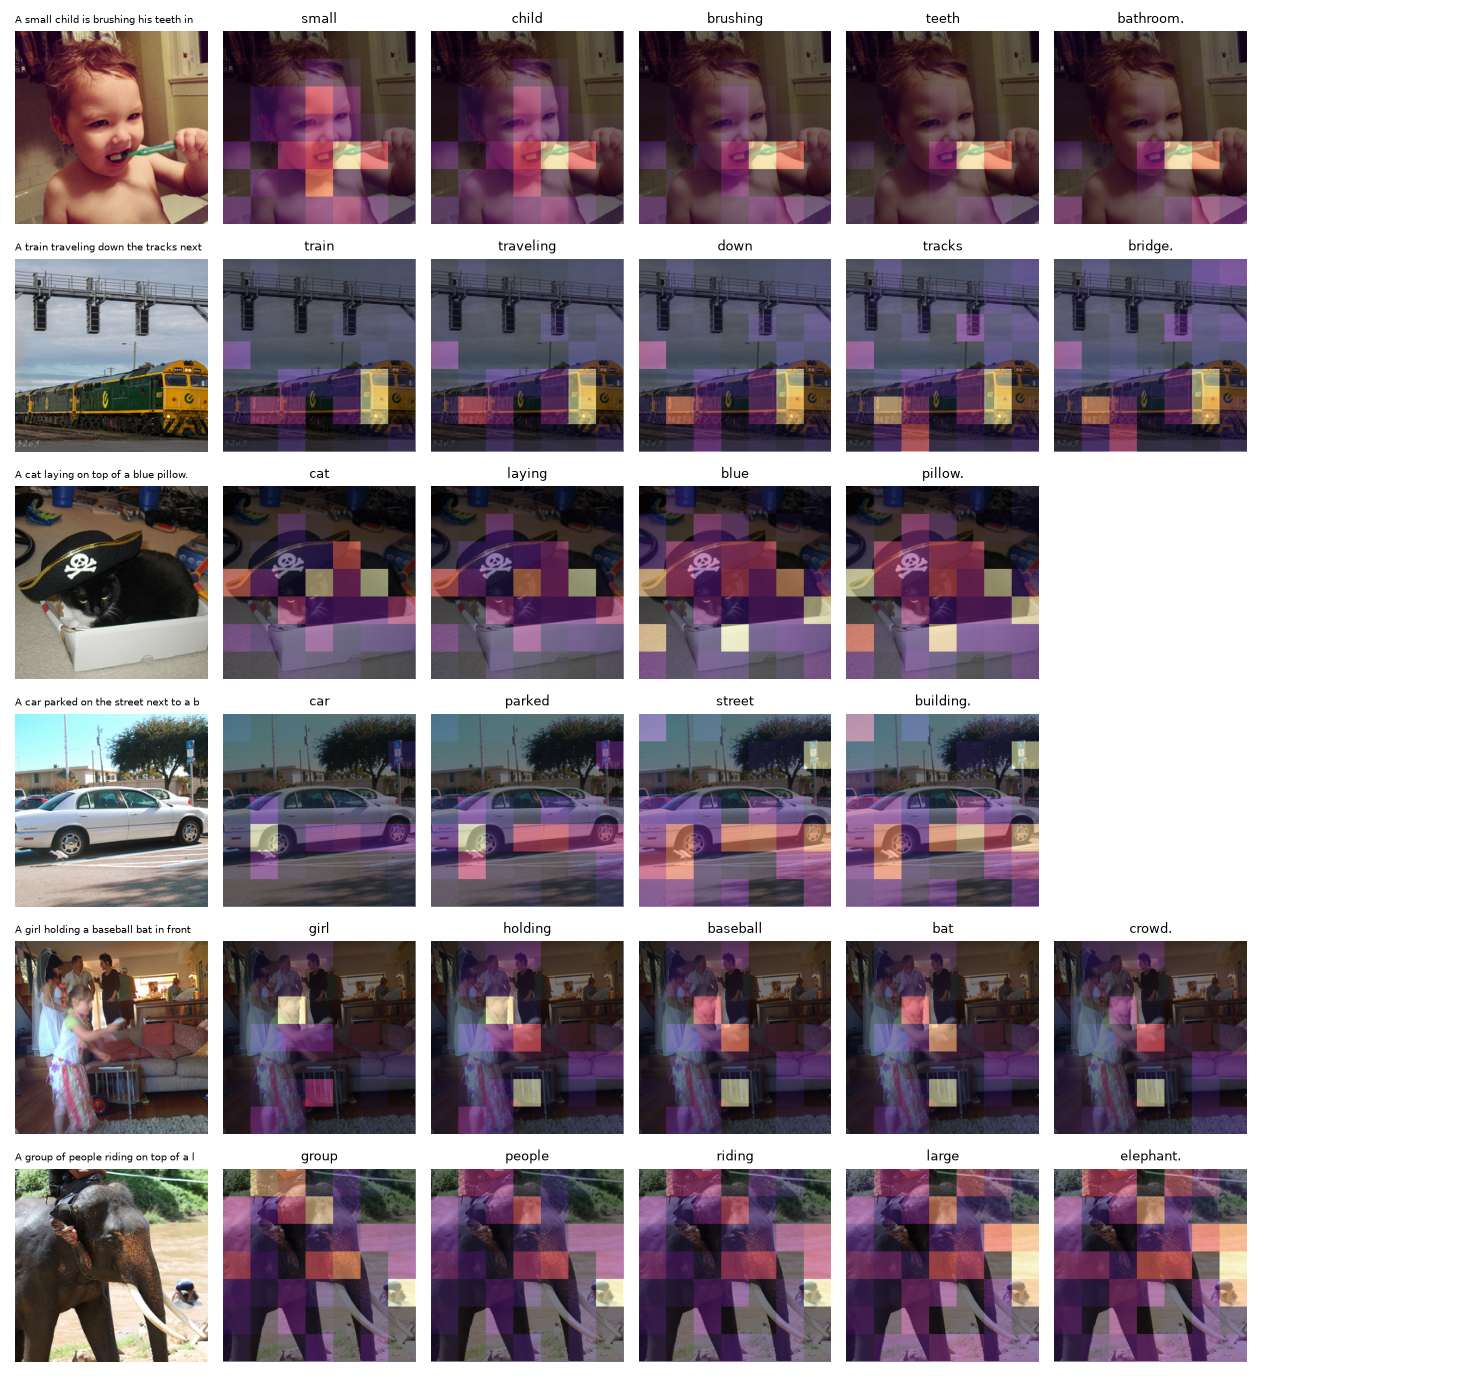

In [13]:
att = {p.stem.replace("_grounding", ""): json.loads(p.read_text())["summary"]
       for p in sorted(Path("results/attention").glob("*_grounding.json"))}
display(pd.DataFrame(att).T)
for p in sorted(Path("results/attention").glob("*_heatmaps.png"))[:1]:
    display(Show(str(p)))

## 7 · Image → caption → image cycle (extra)

Each caption is turned back into an image with Stable Diffusion v1.5 (same seed per image for every source);
similarity = cosine of CLIP image embeddings, regenerated vs original. Images in this section are AI-generated.

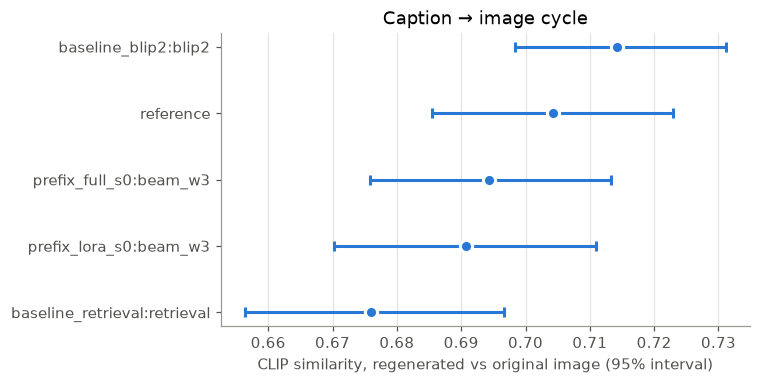

,mean_similarity,lo,hi,n,nsfw_flagged
baseline_retrieval:retrieval,0.6760,0.6564,0.6967,100.0,0.0
prefix_lora_s0:beam_w3,0.6908,0.6703,0.7109,100.0,0.0
prefix_full_s0:beam_w3,0.6944,0.6759,0.7133,100.0,0.0
reference,0.7042,0.6854,0.7229,100.0,0.0
baseline_blip2:blip2,0.7143,0.6984,0.7311,100.0,0.0


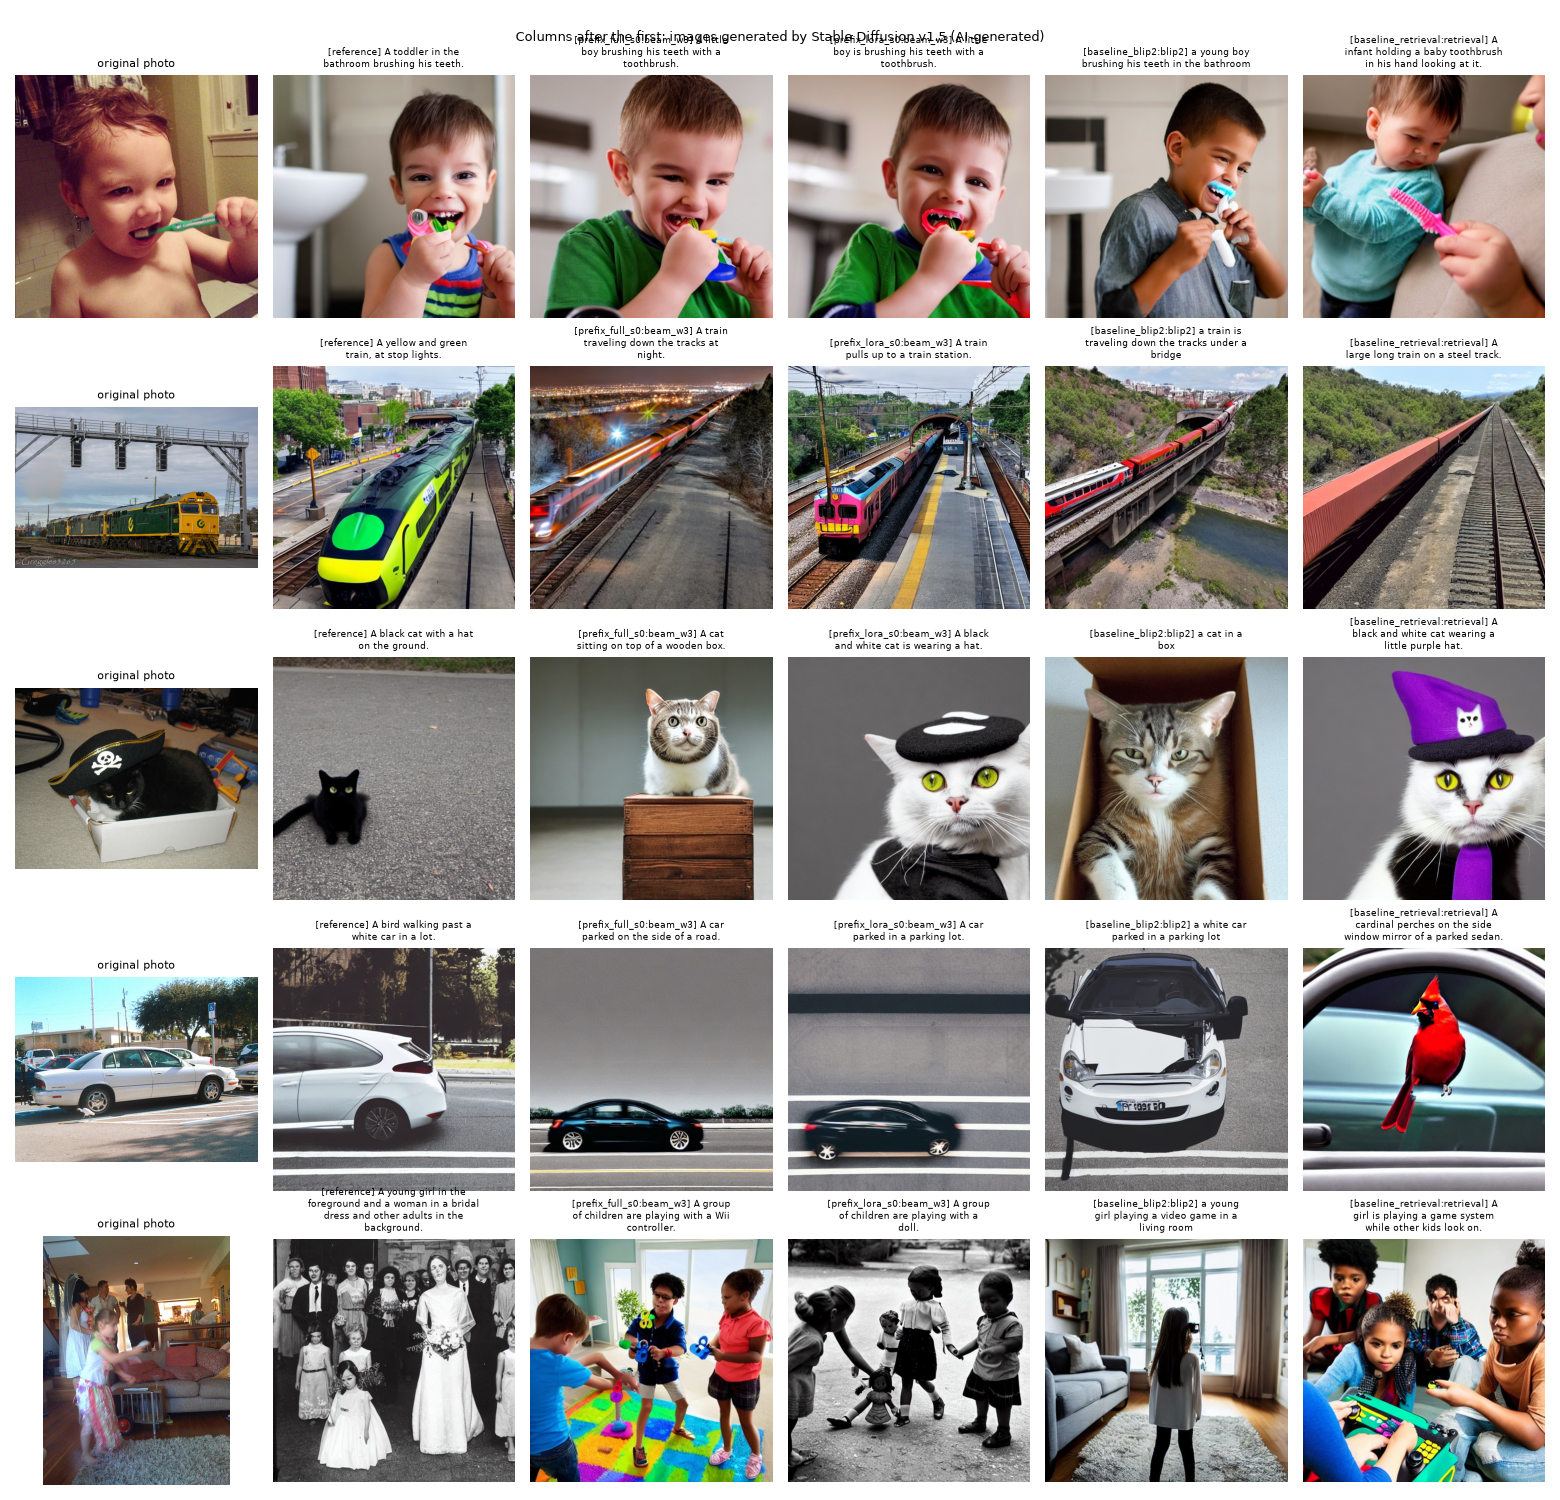

In [14]:
cy = Path("results/cycle/summary.json")
if cy.exists():
    c = pd.DataFrame(json.loads(cy.read_text())["sources"]).T.sort_values("mean_similarity")
    fig, ax = plt.subplots(figsize=(6.2, 0.45 * len(c) + 1.2))
    ax.errorbar(c.mean_similarity, range(len(c)), xerr=[c.mean_similarity - c.lo, c.hi - c.mean_similarity],
                fmt="o", ms=8, color=SERIES[0], mec="white", mew=2, capsize=3)
    ax.set_yticks(range(len(c))); ax.set_yticklabels(c.index); ax.grid(axis="y", visible=False)
    ax.set(xlabel="CLIP similarity, regenerated vs original image (95% interval)", title="Caption → image cycle")
    save(fig, "cycle_similarity"); display(c)
    display(Show("results/cycle/cycle_gallery.png"))
else:
    print("no cycle results yet")

## 8 · Qualitative comparison

Same test images, every system side by side (seed 0 of each round-2 config, beam width 3).

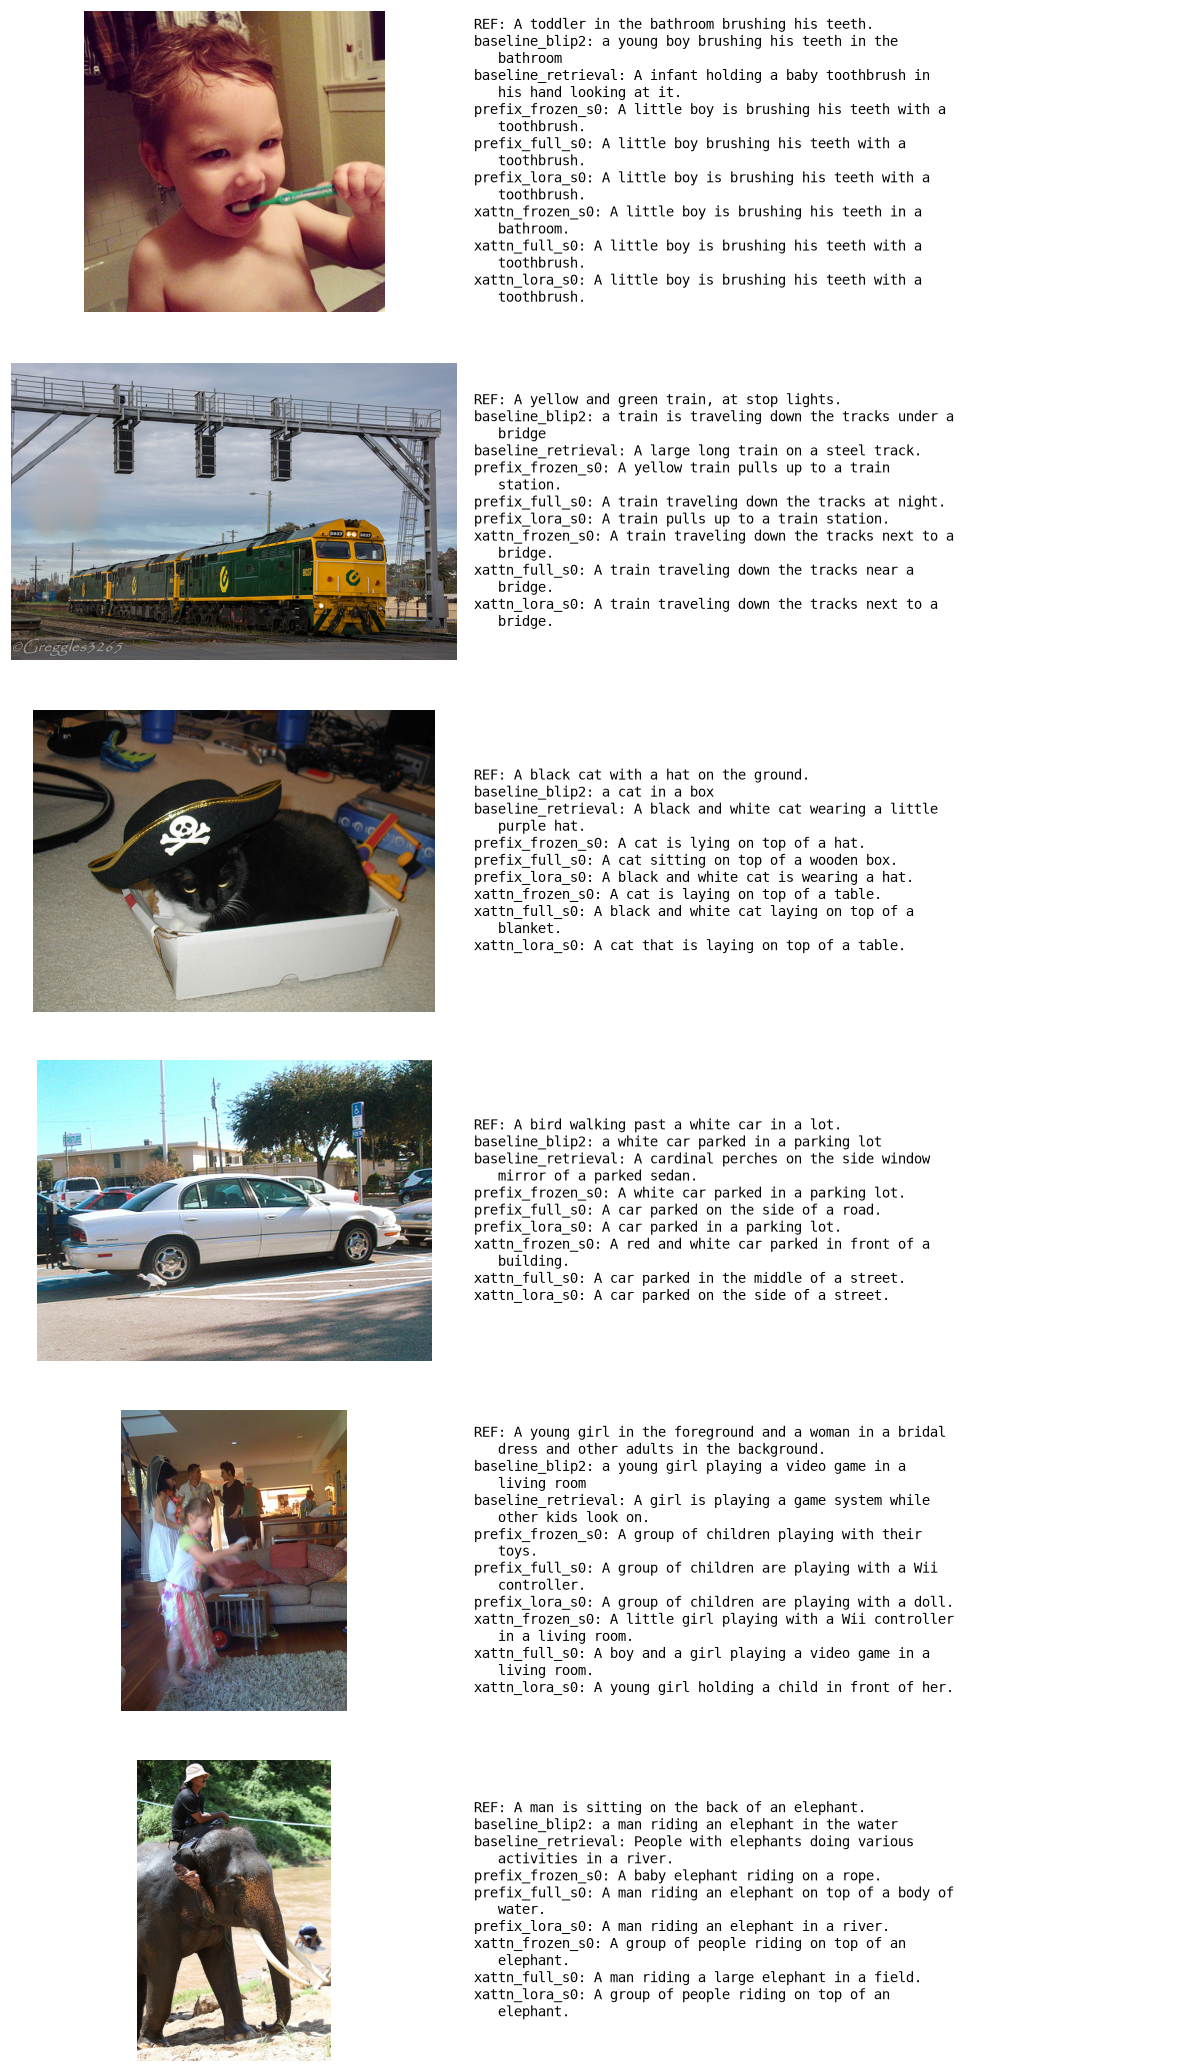

In [15]:
from src import data
from src.evaluate import save_gallery
caps = data.load_captions()
cols = {}
for f in sorted(Path("results").glob("*/*_test.json")):
    keep = (re.fullmatch(r".+_s0", f.parent.name) and "_n" not in f.parent.name and f.stem == "beam_w3_test") \
           or f.stem in ("retrieval_test", "blip2_test")
    if keep:
        cols[f.parent.name] = json.loads(f.read_text(encoding="utf-8"))["captions"]
ids = list(next(iter(cols.values())))[:6] if cols else []
Show(str(save_gallery(ids, cols, caps, Path("results/m3_qualitative.png"), width=60))) if ids else "no results yet"